# Aula 8 – Agrupamento e identificação de padrões operacionais

## Versão do aluno

### Objetivo da aula
Aplicar o algoritmo **K-means** para identificar grupos de comportamento operacional em uma base de dados industrial.

### Instruções
Complete as células indicadas e registre suas interpretações ao longo da atividade.


## 1. Importação das bibliotecas

Importe as bibliotecas necessárias para leitura da base, visualização, padronização e agrupamento.


In [ ]:
# Importe a biblioteca `pandas` utilizando o alias `pd` para manipulação e análise de tabelas e datasets.
# Importe a biblioteca `numpy` utilizando o alias `np` para realizar operações matemáticas e numéricas.
# Importe a biblioteca `matplotlib.pyplot` utilizando o alias `plt` para criação e exibição de gráficos.
# Importe a biblioteca `seaborn` utilizando o alias `sns` para criação de gráficos estatísticos e visualização dos dados.
# Importe a classe `StandardScaler` do módulo `sklearn.preprocessing` para padronizar as variáveis numéricas antes do agrupamento.
# Importe a classe `KMeans` do módulo `sklearn.cluster` para realizar o agrupamento dos dados em diferentes clusters.
# Importe a função `silhouette_score` do módulo `sklearn.metrics` para avaliar a qualidade dos agrupamentos gerados pelo algoritmo K-Means.
# Configure o pandas para exibir todas as colunas disponíveis do DataFrame durante a análise dos dados.

In [1]:

# Importação das bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Importação das ferramentas de aprendizado de máquina
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Exibir todas as colunas dos DataFrames
pd.set_option('display.max_columns', None)

## 2. Leitura da base

Leia o arquivo `dados_aula8_kmeans_industrial.csv` e mostre as primeiras linhas.


In [ ]:
# Utilize a função `read_csv` do pandas para carregar o arquivo CSV `dados_aula8_kmeans_industrial.csv` em um DataFrame chamado `df`.
# Utilize o método `head()` para visualizar as primeiras linhas do dataset e verificar se os dados foram carregados corretamente.

In [2]:
# Complete aqui
df = pd.read_csv('/content/dados_aula8_kmeans_industrial.csv')
df.head()

,id_registro,linha,turno,produto,vazao_l_min,pressao_bar,temperatura_c,vibracao_mm_s,consumo_energia_kwh,tempo_resposta_s,erro_vazao_pct,leituras_invalidas,abertura_valvula_pct,estado_operacional_referencia
0,REG_0001,Linha_C,Manhã,Base,122.980285,3.520386,42.788341,1.338362,18.467412,1.492479,1.950425,0,53.539009,Estavel
1,REG_0002,Linha_C,Manhã,Solvente,119.170414,3.703415,40.919981,1.062157,19.379465,1.614617,1.596653,2,43.449158,Estavel
2,REG_0003,Linha_A,Noite,Acido,123.886131,3.352569,40.650675,1.311664,17.902116,NaN,1.895365,1,45.259073,Estavel
3,REG_0004,Linha_A,Tarde,Base,129.138179,3.431191,42.607915,4.203438,18.361541,1.560486,2.059482,1,55.716320,Estavel
4,REG_0005,Linha_B,Manhã,Acido,118.595080,3.417657,41.718437,1.105775,18.621130,1.436369,1.355104,0,52.854327,Estavel


## 3. Inspeção inicial

Verifique a dimensão da base, os tipos de dados, os valores faltantes e a quantidade de duplicatas.

**Registro técnico:**
- Quais colunas exigem tratamento?
- Há duplicatas?
- O que precisa ser ajustado antes de aplicar o K-means?


In [ ]:
# Utilize `df.shape` para verificar a dimensão do dataset, identificando a quantidade de linhas e colunas.
# Utilize `df.dtypes` para verificar o tipo de dado armazenado em cada coluna.
# Utilize `df.isna().sum()` para identificar a quantidade de valores ausentes em cada coluna.
# Utilize `df.duplicated().sum()` para verificar se existem registros duplicados no dataset.
# Analise os resultados para identificar possíveis problemas que precisam ser tratados antes da aplicação do modelo.

In [ ]:
# Inspecionar a estrutura e a qualidade da base de dados

print('Dimensão da base:', df.shape)

print('\nTipos de dados:')
print(df.dtypes)

print('\nValores faltantes:')
print(df.isna().sum())

print('\nDuplicatas:', df.duplicated().sum())

Dimensão da base: (270, 14)

Tipos de dados:
id_registro                       object
linha                             object
turno                             object
produto                           object
vazao_l_min                      float64
pressao_bar                      float64
temperatura_c                    float64
vibracao_mm_s                    float64
consumo_energia_kwh              float64
tempo_resposta_s                 float64
erro_vazao_pct                   float64
leituras_invalidas                 int64
abertura_valvula_pct             float64
estado_operacional_referencia     object
dtype: object

Valores faltantes:
id_registro                      0
linha                            0
turno                            0
produto                          9
vazao_l_min                      0
pressao_bar                      8
temperatura_c                    9
vibracao_mm_s                    0
consumo_energia_kwh              0
tempo_resposta_s                

**Registro do aluno:**

-produto (9 faltantes), pressao_bar (8), temperatura_c (9) e tempo_resposta_s (9).

-Não, zero duplicatas.

-Preencher os faltantes (mediana nas numéricas, moda na categórica), excluir colunas categóricas e o id_registro da entrada do modelo, e padronizar as variáveis numéricas com StandardScale

## 4. Tratamento inicial

- Remova duplicatas.
- Trate valores faltantes numéricos com a mediana.
- Trate valores faltantes categóricos com a moda.


In [ ]:
# Utilize o método `drop_duplicates()` do pandas para remover registros duplicados do DataFrame.
# Em seguida, utilize o método `copy()` para criar uma cópia independente do DataFrame após a remoção das duplicatas.

# Crie a lista `colunas_numericas` contendo os nomes das colunas que armazenam valores numéricos.
# Essa lista será utilizada para aplicar o mesmo tratamento de valores ausentes em todas as variáveis numéricas.

# Utilize um laço `for` para percorrer cada coluna armazenada na lista `colunas_numericas`.
# Para cada coluna, utilize o método `fillna()` para substituir os valores ausentes.
# Dentro do `fillna()`, utilize o método `median()` para calcular a mediana da respectiva coluna.
# A mediana será utilizada como valor de preenchimento porque é menos sensível à influência de valores extremos.

# Crie um segundo laço `for` para percorrer as colunas categóricas `linha`, `turno` e `produto`.
# Utilize novamente o método `fillna()` para substituir os valores ausentes dessas colunas.
# Utilize o método `mode()` para identificar o valor que aparece com maior frequência em cada coluna.
# Utilize `[0]` para selecionar o primeiro valor retornado pela função `mode()` e utilizá-lo como preenchimento.

# Utilize a propriedade `shape` do DataFrame para verificar sua dimensão após a limpeza.
# A propriedade `shape` retorna a quantidade de linhas e colunas existentes no DataFrame.

# Utilize o método `isna()` para identificar os valores ausentes existentes no DataFrame.
# Em seguida, utilize o método `sum()` para contabilizar a quantidade de valores ausentes em cada coluna.
# Analise o resultado para confirmar se o tratamento dos dados ausentes foi realizado corretamente.

In [3]:

# Remover linhas duplicadas
df = df.drop_duplicates().copy()

# Definir as variáveis numéricas do processo industrial
colunas_numericas = [
    'vazao_l_min', 'pressao_bar', 'temperatura_c', 'vibracao_mm_s',
    'consumo_energia_kwh', 'tempo_resposta_s', 'erro_vazao_pct',
    'leituras_invalidas', 'abertura_valvula_pct'
]

# Preencher valores numéricos ausentes com a mediana
for col in colunas_numericas:
    df[col] = df[col].fillna(df[col].median())

# Preencher valores categóricos ausentes com a moda
colunas_categoricas = ['linha', 'turno', 'produto']

for col in colunas_categoricas:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# Verificar valores ausentes após o tratamento
print('Valores ausentes após o tratamento:')
print(df.isna().sum())

print('\nTotal de valores ausentes:', df.isna().sum().sum())

Valores ausentes após o tratamento:
id_registro                      0
linha                            0
turno                            0
produto                          0
vazao_l_min                      0
pressao_bar                      0
temperatura_c                    0
vibracao_mm_s                    0
consumo_energia_kwh              0
tempo_resposta_s                 0
erro_vazao_pct                   0
leituras_invalidas               0
abertura_valvula_pct             0
estado_operacional_referencia    0
dtype: int64

Total de valores ausentes: 0


## 5. Seleção das features

Monte a matriz `X` usando apenas as variáveis numéricas do processo.

**Pergunta:**  
Por que a coluna `estado_operacional_referencia` não deve ser usada como entrada do K-means?


In [ ]:
# Crie o DataFrame `X` selecionando, por meio de `df[colunas_numericas]`, apenas as variáveis numéricas que serão utilizadas no K-Means.
# Utilize o método `copy()` para criar uma cópia independente dos dados selecionados.
# Utilize o método `head()` para visualizar as primeiras linhas de `X` e conferir os dados selecionados.

In [5]:
# Complete aqui
X = df[colunas_numericas].copy()
X.head()

,vazao_l_min,pressao_bar,temperatura_c,vibracao_mm_s,consumo_energia_kwh,tempo_resposta_s,erro_vazao_pct,leituras_invalidas,abertura_valvula_pct
0,122.980285,3.520386,42.788341,1.338362,18.467412,1.492479,1.950425,0,53.539009
1,119.170414,3.703415,40.919981,1.062157,19.379465,1.614617,1.596653,2,43.449158
2,123.886131,3.352569,40.650675,1.311664,17.902116,2.277365,1.895365,1,45.259073
3,129.138179,3.431191,42.607915,4.203438,18.361541,1.560486,2.059482,1,55.716320
4,118.595080,3.417657,41.718437,1.105775,18.621130,1.436369,1.355104,0,52.854327


**Resposta do aluno:**

Porque ela é a variável que representa o resultado real que se quer descobrir — usá-la como entrada seria "entregar a resposta" ao algoritmo, e o K-means deixaria de ser um agrupamento não supervisionado. Ela deve ficar de fora do treinamento e servir só depois, para comparar (via crosstab) se os clusters encontrados batem com os estados operacionais conhecidos.

## 6. Padronização

Padronize as variáveis com `StandardScaler`.

**Pergunta:**  
Por que a padronização é importante antes do K-means?


In [ ]:
# Crie um objeto `StandardScaler()` para realizar a padronização das variáveis numéricas.
# Utilize o método `fit_transform()` para calcular os parâmetros de padronização e transformar os dados de `X`.
# Armazene os dados padronizados em `X_scaled`.
# Utilize `[:5]` para visualizar as cinco primeiras linhas dos dados padronizados.

In [6]:
# Complete aqui
# Padronizar as variáveis numéricas antes do K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Exibir as cinco primeiras observações padronizadas
X_scaled[:5]

array([[ 0.10124033, -0.02549359, -0.30541223, -0.9049264 , -0.67284053,
        -0.99293185, -1.13693772, -1.58258215,  0.00458417],
       [-0.07246552,  0.23781817, -0.56331686, -1.16114478, -0.44789565,
        -0.87500152, -1.33454717, -0.50490956, -0.81799044],
       [ 0.14254115, -0.26692127, -0.60049133, -0.92969297, -0.81226271,
        -0.23508793, -1.16769297, -1.04374586, -0.67043722],
       [ 0.3820011 , -0.15381293, -0.33031783,  1.75282832, -0.69895218,
        -0.92726794, -1.07602036, -1.04374586,  0.18208939],
       [-0.0986971 , -0.1732829 , -0.45309966, -1.1206831 , -0.63492825,
        -1.04710804, -1.4694712 , -1.58258215, -0.05123447]])

**Resposta do aluno:**
 A padronização coloca todas as variáveis na mesma escala (média 0, desvio padrão 1), garantindo que cada uma contribua de forma equilibrada para a formação dos clusters.


## 7. Teste de valores de k

Calcule a inércia e o silhouette score para valores de `k` entre 2 e 7.


# 🔹 K-Means — Identificação de Perfis Operacionais

### Pergunta de negócio

**É possível identificar diferentes perfis de operação das máquinas
a partir de suas características de funcionamento?**

Sim. É possível identificar diferentes perfis de operação das máquinas utilizando o algoritmo K-Means, que agrupa registros com características de funcionamento semelhantes, como vazão, pressão, temperatura, vibração, consumo de energia e tempo de resposta.
Após a padronização das variáveis, o algoritmo pode identificar grupos com padrões operacionais distintos, permitindo investigar comportamentos como operação estável, instabilidade e sobrecarga. Posteriormente, os clusters encontrados podem ser comparados com a coluna estado_operacional_referencia para verificar se os agrupamentos correspondem aos estados conhecidos.

In [ ]:
# Crie uma lista vazia chamada `inercias`.
# Crie uma lista vazia chamada `silhuetas`.
# Crie `k_range` utilizando `range(2, 8)` para gerar os valores de `k` de 2 até 7.
# Percorra os valores de `k_range` utilizando um laço `for`.
# Para cada valor de `k`, crie um modelo `KMeans` definindo `n_clusters=k`, `random_state=42` e `n_init=10`.
# Utilize o método `fit_predict()` do modelo para treinar o K-Means com os dados `X_scaled` e armazenar os grupos em `grupos_temp`.
# Utilize a propriedade `inertia_` do modelo e adicione seu valor à lista `inercias` com o método `append()`.
# Utilize a função `silhouette_score()` com `X_scaled` e `grupos_temp` e adicione o resultado à lista `silhuetas` com o método `append()`.
# Crie o DataFrame `resultados_k` utilizando `pd.DataFrame()`.
# Crie a coluna `k` utilizando `list(k_range)`.
# Crie a coluna `inercia` utilizando a lista `inercias`.
# Crie a coluna `silhouette` utilizando a lista `silhuetas`.
# Exiba o DataFrame `resultados_k`.

In [7]:
inercias = []
silhuetas = []
k_range = range(2, 8)

for k in k_range:
    modelo_temp = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    grupos_temp = modelo_temp.fit_predict(X_scaled)

    # Armazenar a inércia e o coeficiente de silhueta
    inercias.append(modelo_temp.inertia_)
    silhuetas.append(
        silhouette_score(X_scaled, grupos_temp)
    )

# Organizar os resultados em uma tabela
resultados_k = pd.DataFrame({
    'k': list(k_range),
    'inercia': inercias,
    'silhouette': silhuetas
})

display(resultados_k)


,k,inercia,silhouette
0,2,1171.970379,0.535022
1,3,460.166777,0.660713
2,4,377.675108,0.669010
3,5,326.773598,0.672361
4,6,310.934186,0.510906
5,7,278.327373,0.557876


### Explicando `k_range = range(2,8)`:

* K=0 → K-Means não pode ter zero clusters.
* K=1 → Não é adequado para calcular o Silhouette Score, pois é necessário ter pelo menos 2 grupos.

In [ ]:
# Crie uma nova figura usando `plt.figure()` com tamanho `figsize=(8, 4)`.

# Crie um gráfico de linha usando `plt.plot()`.
# Utilize `resultados_k['k']` no eixo X, representando o número de clusters.
# Utilize `resultados_k['inercia']` no eixo Y, representando a inércia.
# Utilize `marker='o'` para marcar cada ponto da linha.

# Defina o título do gráfico com `plt.title()`: 'Método do cotovelo'.

# Defina o nome do eixo X usando `plt.xlabel()`: 'Número de clusters (k)'.

# Defina o nome do eixo Y usando `plt.ylabel()`: 'Inércia'.

# Exiba o gráfico utilizando `plt.show()`.


# Crie uma segunda figura usando `plt.figure()` com tamanho `figsize=(8, 4)`.

# Crie um gráfico de linha usando `plt.plot()`.
# Utilize `resultados_k['k']` no eixo X, representando o número de clusters.
# Utilize `resultados_k['silhouette']` no eixo Y, representando o Silhouette Score.
# Utilize `marker='o'` para marcar cada ponto da linha.

# Defina o título do gráfico com `plt.title()`: 'Silhouette score por número de clusters'.

# Defina o nome do eixo X usando `plt.xlabel()`: 'Número de clusters (k)'.

# Defina o nome do eixo Y usando `plt.ylabel()`: 'Silhouette'.

# Exiba o gráfico utilizando `plt.show()`.

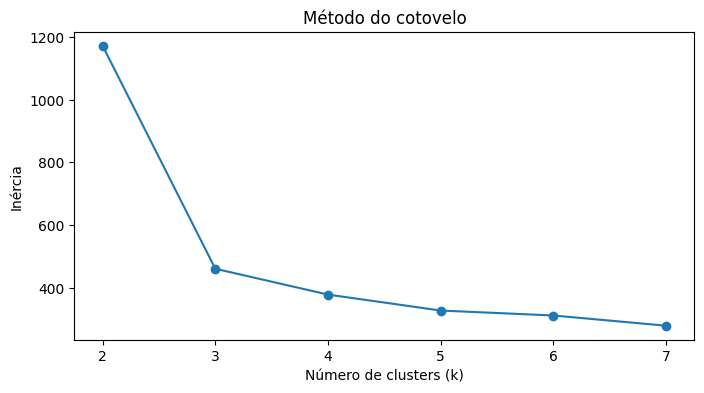

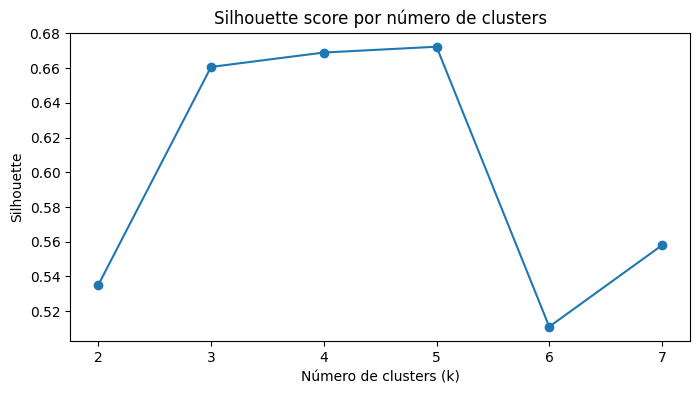

In [ ]:
# Gere os gráficos aqui
plt.figure(figsize=(8,4))

plt.plot(resultados_k['k'], resultados_k['inercia'], marker='o')
plt.title('Método do cotovelo')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inércia')
plt.show()

plt.figure(figsize=(8,4))
plt.plot(resultados_k['k'], resultados_k['silhouette'], marker='o')
plt.title('Silhouette score por número de clusters')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette')
plt.show()

### ***Explicando o teste***

>Não existe uma inércia ideal ou um valor mínimo universal.<br/>
>No K-Means, a inércia sempre diminui quando aumentamos o número de clusters. Por isso, não basta escolher o menor valor.

***cotovelo*** é o ponto em que aumentar K deixa de trazer uma redução significativa da inércia.

> "O teste indica que os dados possuem uma estrutura de agrupamento razoavelmente bem definida, principalmente entre 3 e 5 grupos. O próximo passo é analisar os clusters para entender o significado operacional de cada grupo."

### Inércia
> Inércia = soma das distâncias quadráticas de cada registro até o centróide do seu cluster.
> O Centroide é a media aritimetica do grupo, e depois obtem a soma das distâncias euclidianas ao quadrado de cada registro até o centróide do seu cluster.

### Silhueta
 > O quão bem o registro se encaixa no seu grupo e se separa dos demais.

## 8. Escolha do número de clusters

Escolha um valor de `k` e justifique sua decisão com base nos resultados.


**Justificativa do aluno:**
A inércia cai de forma brusca de k=2 para k=3 (de 1172 para 460), mas depois passa a diminuir de forma mais suave e gradual — esse é o "cotovelo" do gráfico. O silhouette score também confirma: passa de 0,535 (k=2) para 0,661 (k=3), e daí em diante os ganhos são pequenos (0,669 em k=4, 0,672 em k=5) até cair em k=6. Ou seja, k=3 já captura a maior parte da estrutura dos dados com clusters bem separados, e aumentar k mais não traz ganho relevante — só adiciona complexidade sem melhorar a qualidade do agrupamento.


## 9. Criação do modelo K-means

Crie o modelo com o valor de `k` escolhido, ajuste aos dados padronizados e gere os clusters.


In [ ]:
# Crie o modelo `KMeans` definindo n_clusters=`3`, `random_state=42` e `n_init=10`.
# Utilize o método `fit_predict()` com `X_scaled` para treinar o modelo e obter o cluster de cada registro.
# Armazene os grupos gerados na variável `clusters`.
# Crie a coluna `cluster` no DataFrame `df` e atribua os grupos armazenados em `clusters`.
# Selecione as colunas `id_registro` e `cluster` do DataFrame e utilize o método `head()` para visualizar os primeiros registros.

In [ ]:

# Criando o modelo KMeans
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Treinando o modelo e obtendo o cluster de cada registro
clusters = kmeans.fit_predict(X_scaled)

# Armazenando os grupos no DataFrame
df['cluster'] = clusters

# Visualizando os primeiros registros
df[['id_registro', 'cluster']].head()

,id_registro,cluster
0,REG_0001,2
1,REG_0002,2
2,REG_0003,2
3,REG_0004,2
4,REG_0005,2


## 10. Interpretação dos clusters

Calcule a média das variáveis numéricas por cluster e interprete o perfil de cada grupo e responda.

* qual grupo tem maior vibração; <br/>
* qual grupo parece mais estável; <br/>
* qual grupo apresenta maior erro ou maior tempo de resposta.

In [ ]:
# Agrupe o DataFrame `df` pela coluna `cluster` utilizando o método `groupby()`.
# Selecione as colunas numéricas definidas em `colunas_numericas`.
# Calcule a média de cada variável numérica dentro de cada cluster utilizando o método `mean()`.
# Arredonde os resultados para 2 casas decimais utilizando o método `round(2)`.
# Armazene o resultado na variável `perfil_clusters`.
# Exiba `perfil_clusters` para visualizar o perfil médio de cada cluster.

In [ ]:
# Agrupar o DataFrame `df` pela coluna `cluster`, selecionar as colunas numéricas,
# calcular a média por cluster e arredondar para 2 casas decimais.
perfil_clusters = df.groupby('cluster')[colunas_numericas].mean().round(2)

# Exibir o perfil médio de cada cluster
display(perfil_clusters)

,vazao_l_min,pressao_bar,temperatura_c,vibracao_mm_s,consumo_energia_kwh,tempo_resposta_s,erro_vazao_pct,leituras_invalidas,abertura_valvula_pct
cluster,,,,,,,,,
0,146.93,4.34,54.50,2.25,25.30,2.37,4.28,3.04,67.84
1,94.85,2.73,38.39,3.52,20.34,3.76,6.04,4.94,40.14
2,119.41,3.51,41.96,1.27,18.05,1.53,1.83,1.00,51.95


In [ ]:
# Utilize a coluna `cluster` do DataFrame `df`.
# Utilize o método `value_counts()` para contar a quantidade de registros pertencentes a cada cluster.
# Utilize o método `sort_index()` para ordenar os clusters pelo seu índice.
# Exiba o resultado para verificar a quantidade de registros em cada cluster.

In [ ]:
df['cluster'].value_counts().sort_index()

,count
cluster,
0,90
1,86
2,94


**Interpretação do aluno:**
### Interpretação dos perfis dos clusters

**1. Qual grupo tem maior vibração?**

O **Cluster 1**, com vibração média de **3,52 mm/s**, apresenta o maior nível de vibração entre os três grupos. Esse resultado pode indicar maior intensidade de vibrações mecânicas e merece atenção na análise das condições operacionais das máquinas.

**2. Qual grupo parece mais estável?**

O **Cluster 2** parece representar o perfil operacional mais estável, pois apresenta a menor vibração média (1,27 mm/s), o menor erro de vazão (1,83%), o menor tempo de resposta (1,53 s) e a menor quantidade média de leituras inválidas (1,00). Em conjunto, essas características sugerem um processo mais controlado e com menos sinais de anormalidade.

**3. Qual grupo apresenta maior erro ou maior tempo de resposta?**

O **Cluster 1** apresenta tanto o maior erro médio de vazão (6,04%) quanto o maior tempo médio de resposta (3,76 s). Também possui a maior média de leituras inválidas (4,94), reforçando a hipótese de um perfil operacional mais instável ou fora do padrão esperado.

**4. Como interpretar o Cluster 0?**

O **Cluster 0** apresenta um perfil de operação mais intensa, com as maiores médias de vazão (146,93 L/min), pressão (4,34 bar), temperatura (54,50 °C) e consumo de energia (25,30 kWh). Entretanto, sua vibração média (2,25 mm/s), seu erro de vazão (4,28%) e seu tempo de resposta (2,37 s) ficam entre os valores observados nos outros grupos. Isso sugere um perfil de operação de maior carga, sem que seja possível concluir apenas por essas médias que exista uma falha ou uma condição plenamente controlada.


## 11. Visualização dos agrupamentos

Crie um gráfico de dispersão com duas variáveis importantes do processo e use a cor para distinguir os clusters.


In [ ]:
# Crie uma figura com tamanho 8x6 utilizando `plt.figure(figsize=(8,6))`.
# Crie um gráfico de dispersão utilizando `sns.scatterplot()`.
# Utilize o DataFrame `df` como fonte dos dados por meio do parâmetro `data`.
# Defina `vazao_l_min` como variável do eixo X utilizando `x`.
# Defina `vibracao_mm_s` como variável do eixo Y utilizando `y`.
# Utilize `cluster` em `hue` para diferenciar os clusters por cores.
# Utilize `cluster` em `style` para diferenciar os clusters também pelos símbolos dos pontos.
# Defina o tamanho dos pontos como 80 utilizando `s`.
# Defina o título do gráfico como `Clusters observados em vazão x vibração` utilizando `plt.title()`.
# Exiba o gráfico utilizando `plt.show()`.

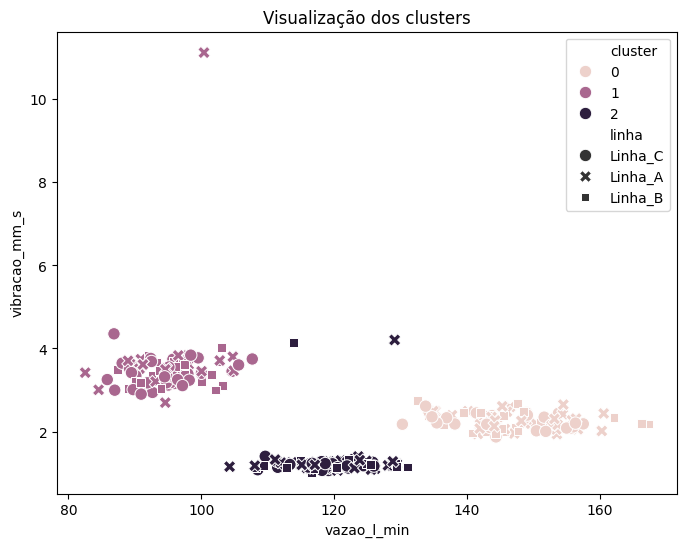

In [ ]:
# Complete aqui
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x='vazao_l_min',
    y='vibracao_mm_s',
    hue='cluster',
    style='linha',
    s=80
)
plt.title('Visualização dos clusters')
plt.show()

## 12. Comparação com a coluna de referência

Monte uma tabela cruzada entre `cluster` e `estado_operacional_referencia`.

**Pergunta:**  
Os agrupamentos encontrados se aproximam de padrões operacionais reconhecíveis?


In [ ]:
# Utilize a função `crosstab()` do pandas para cruzar os dados de `cluster` com `estado_operacional_referencia`.
# Utilize `df['cluster']` como a primeira variável do cruzamento.
# Utilize `df['estado_operacional_referencia']` como a segunda variável do cruzamento.
# Exiba a tabela resultante para comparar a distribuição dos estados operacionais dentro de cada cluster.

In [ ]:
# Complete aqui
pd.crosstab(df['cluster'], df['estado_operacional_referencia'])

estado_operacional_referencia,Estavel,Instavel,Sobrecarga
cluster,,,
0,0,0,90
1,0,86,0
2,94,0,0


* O pd.crosstab() cria uma tabela de contagem cruzada. Em termos simples:<br/>
`Ele conta quantas vezes cada combinação de valores aparece.`


>"O K-Means descobriu os grupos sem conhecer os estados operacionais. Depois de criar os clusters, usamos a coluna de referência apenas para verificar se os grupos encontrados correspondem aos estados conhecidos. Neste caso, a correspondência foi perfeita."

**Resposta do aluno:**



## 13. Não supervisionado x supervisionado

Explique, com suas palavras:
- o que caracteriza uma abordagem não supervisionada;
- como ela difere da supervisionada;
- como o agrupamento pode ajudar no contexto industrial.


**Resposta do aluno:**

**1. O que caracteriza uma abordagem não supervisionada?**

Uma abordagem não supervisionada utiliza dados sem rótulos previamente definidos para identificar padrões, semelhanças ou grupos. No projeto, o K-Means agrupa os registros das máquinas com base em suas características operacionais, como vazão, pressão, temperatura e vibração, sem conhecer previamente o estado de cada registro.

**2. Como ela difere da supervisionada?**

Na aprendizagem não supervisionada, o algoritmo procura padrões nos dados sem utilizar respostas conhecidas durante o treinamento. Já na aprendizagem supervisionada, o modelo aprende a partir de exemplos que possuem rótulos ou resultados conhecidos, como registros classificados como estáveis, instáveis ou em sobrecarga. Assim, enquanto o K-Means busca descobrir grupos, um modelo supervisionado pode aprender a classificar novos registros nesses estados.

**3. Como o agrupamento pode ajudar no contexto industrial?**

O agrupamento pode ajudar a identificar diferentes perfis de funcionamento das máquinas, detectar comportamentos incomuns e reconhecer padrões associados a possíveis problemas operacionais. Neste projeto, os clusters permitem comparar máquinas com características semelhantes e identificar grupos com maior vibração, erro de vazão ou tempo de resposta. Essas informações podem apoiar o monitoramento dos equipamentos, a investigação de anomalias e o planejamento da manutenção preventiva, contribuindo para reduzir falhas e paradas inesperadas.

## 14. Exportação da base final

Salve a base com a nova coluna `cluster`.


In [ ]:
# Complete aqui
df.to_csv('dados_clusterizados.csv', index=False)
print('Arquivo exportado com sucesso.')

Arquivo exportado com sucesso.


## 15. Fechamento

Verifique se você:
- implementou corretamente o agrupamento;
- interpretou os padrões encontrados;
- registrou tecnicamente os resultados;
- organizou adequadamente os arquivos do experimento.
